# Tp << Inteligence artificielle pour la cybersecurité >>

## Partie 1 : Découverte a préparation de données 

**Importation des bibliothéques**  
  

Les bibliothéques requises sont dans le fichier **requirements.txt**  
On peut les installer avec la commande : ***pip install -r requirements.txt***

In [1]:
# Dataframes annd array manipulation 

import numpy as np 
import pandas as pd 

# Plotting and figures 

import matplotlib.pyplot as plt 
import seaborn as  sns 

# Machine learning 

from sklearn.preprocessing import StandardScaler , MinMaxScaler , OneHotEncoder
from sklearn.model_selection import train_test_split , GridSearchCV 
from sklearn.metrics import confusion_matrix , accuracy_score , precision_score , recall_score , f1_score
from sklearn.neighbors import KNeighborsClassifier 



In [2]:

df_test = pd.read_csv("NSL-KDD/KDDTest+.txt")
df_train = pd.read_csv("NSL-KDD/KDDTrain+.txt")


print(df_train.head())
print(df_test.head())

   duration protocol_type   service flag  src_bytes  dst_bytes  land  \
0         0           tcp  ftp_data   SF        491          0     0   
1         0           udp     other   SF        146          0     0   
2         0           tcp   private   S0          0          0     0   
3         0           tcp      http   SF        232       8153     0   
4         0           tcp      http   SF        199        420     0   

   wrong_fragment  urgent  hot  ...  dst_host_same_srv_rate  \
0               0       0    0  ...                    0.17   
1               0       0    0  ...                    0.00   
2               0       0    0  ...                    0.10   
3               0       0    0  ...                    1.00   
4               0       0    0  ...                    1.00   

   dst_host_diff_srv_rate  dst_host_same_src_port_rate  \
0                    0.03                         0.17   
1                    0.60                         0.88   
2             

In [3]:
print(df_test.info)
print(df_train.info)

<bound method DataFrame.info of        duration protocol_type   service  flag  src_bytes  dst_bytes  land  \
0             0           tcp   private   REJ          0          0     0   
1             0           tcp   private   REJ          0          0     0   
2             2           tcp  ftp_data    SF      12983          0     0   
3             0          icmp     eco_i    SF         20          0     0   
4             1           tcp    telnet  RSTO          0         15     0   
...         ...           ...       ...   ...        ...        ...   ...   
22539         0           tcp      smtp    SF        794        333     0   
22540         0           tcp      http    SF        317        938     0   
22541         0           tcp      http    SF      54540       8314     0   
22542         0           udp  domain_u    SF         42         42     0   
22543         0           tcp    sunrpc   REJ          0          0     0   

       wrong_fragment  urgent  hot  ...  ds

**Nombre d'observations :**  
- Dans le jeu de données d'entrainement : 125973 observation 
- Dans le jeu de données de test :  22544 observation 

In [4]:
print("Nombre de variables : " , df_test.columns.shape[0]
)

Nombre de variables :  43


In [5]:
# Classe a predire 

print("Classe a predire : " , df_train.columns[-2])

Classe a predire :  sub_attack


In [6]:
# Variables numeriques / catégorielles 

#Variables numériques

print("Les variables numeriques : \n ")
for var in df_train.dtypes[(df_train.dtypes == "int64") | (df_train.dtypes == "float64")].index : 
    print(var)

Les variables numeriques : 
 
duration
src_bytes
dst_bytes
land
wrong_fragment
urgent
hot
num_failed_logins
logged_in
num_compromised
root_shell
su_attempted
num_root
num_file_creations
num_shells
num_access_files
num_outbound_cmds
is_host_login
is_guest_login
count
srv_count
serror_rate
srv_serror_rate
rerror_rate
srv_rerror_rate
same_srv_rate
diff_srv_rate
srv_diff_host_rate
dst_host_count
dst_host_srv_count
dst_host_same_srv_rate
dst_host_diff_srv_rate
dst_host_same_src_port_rate
dst_host_srv_diff_host_rate
dst_host_serror_rate
dst_host_srv_serror_rate
dst_host_rerror_rate
dst_host_srv_rerror_rate
difficulty_level


In [7]:
print("Les variables categorielles : \n ")
for var in df_train.dtypes[(df_train.dtypes != "int64") & (df_train.dtypes != "float64")].index : 
    print(var)


Les variables categorielles : 
 
protocol_type
service
flag
sub_attack


In [8]:
# Les differentes valeurs prises par les variables categorielles : 

print("Les differentes valeurs prises par variables categorielles : \n ")
for var in df_train.dtypes[(df_train.dtypes != "int64") & (df_train.dtypes != "float64")].index : 
    print("La variable " , var , ": \n")
    print(df_train[var].unique().var)
    print("\n\n")

Les differentes valeurs prises par variables categorielles : 
 
La variable  protocol_type : 

<bound method StringArray.var of <StringArray>
['tcp', 'udp', 'icmp']
Length: 3, dtype: str>



La variable  service : 

<bound method StringArray.var of <StringArray>
[   'ftp_data',       'other',     'private',        'http',  'remote_job',
        'name',  'netbios_ns',       'eco_i',         'mtp',      'telnet',
      'finger',    'domain_u',      'supdup',   'uucp_path',      'Z39_50',
        'smtp',    'csnet_ns',        'uucp', 'netbios_dgm',       'urp_i',
        'auth',      'domain',         'ftp',         'bgp',        'ldap',
       'ecr_i',      'gopher',       'vmnet',      'systat',    'http_443',
         'efs',       'whois',       'imap4',    'iso_tsap',        'echo',
      'klogin',        'link',      'sunrpc',       'login',      'kshell',
     'sql_net',        'time',   'hostnames',        'exec',       'ntp_u',
     'discard',        'nntp',     'courier',        

In [9]:

# Verification des valeurs nulls : 
Nulls_train = df_train.isnull().sum()
Nulls_test = df_test.isnull().sum()
print(Nulls_train[Nulls_train != 0])
print(Nulls_test[Nulls_test != 0])

Series([], dtype: int64)
Series([], dtype: int64)


Pas de valeurs nulls 

In [10]:
# Statistiques discriptives 

# jeu de données de test 

df_test.describe()

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,difficulty_level
count,22544.000000,2.254400e+04,2.254400e+04,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,...,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000
mean,218.859076,1.039545e+04,2.056019e+03,0.000311,0.008428,0.000710,0.105394,0.021647,0.442202,0.119899,...,140.750532,0.608722,0.090540,0.132261,0.019638,0.097814,0.099426,0.233385,0.226683,18.017965
std,1407.176612,4.727864e+05,2.121930e+04,0.017619,0.142599,0.036473,0.928428,0.150328,0.496659,7.269597,...,111.783972,0.435688,0.220717,0.306268,0.085394,0.273139,0.281866,0.387229,0.400875,4.270361
min,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,15.000000,0.070000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000
50%,0.000000,5.400000e+01,4.600000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,168.000000,0.920000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000
75%,0.000000,2.870000e+02,6.010000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,255.000000,1.000000,0.060000,0.030000,0.010000,0.000000,0.000000,0.360000,0.170000,21.000000
max,57715.000000,6.282565e+07,1.345927e+06,1.000000,3.000000,3.000000,101.000000,4.000000,1.000000,796.000000,...,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,21.000000


In [11]:
# jeu de donnée d'entrainement 

df_train.describe()

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,difficulty_level
count,125973.00000,1.259730e+05,1.259730e+05,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,...,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000
mean,287.14465,4.556674e+04,1.977911e+04,0.000198,0.022687,0.000111,0.204409,0.001222,0.395736,0.279250,...,115.653005,0.521242,0.082951,0.148379,0.032542,0.284452,0.278485,0.118832,0.120240,19.504060
std,2604.51531,5.870331e+06,4.021269e+06,0.014086,0.253530,0.014366,2.149968,0.045239,0.489010,23.942042,...,110.702741,0.448949,0.188922,0.308997,0.112564,0.444784,0.445669,0.306557,0.319459,2.291503
min,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,10.000000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000
50%,0.00000,4.400000e+01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,63.000000,0.510000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000
75%,0.00000,2.760000e+02,5.160000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,255.000000,1.000000,0.070000,0.060000,0.020000,1.000000,1.000000,0.000000,0.000000,21.000000
max,42908.00000,1.379964e+09,1.309937e+09,1.000000,3.000000,3.000000,77.000000,5.000000,1.000000,7479.000000,...,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,21.000000


In [12]:
# Distribution de labels originaux
print("distribution des labels originaux \n")
print("Dans le jeu d'entrainement \n ")
print(df_train["sub_attack"].value_counts())
print("\n")
print("Dans le jeu de test \n ")
print(df_test["sub_attack"].value_counts())
print("\n")

distribution des labels originaux 

Dans le jeu d'entrainement 
 
sub_attack
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


Dans le jeu de test 
 
sub_attack
normal             9711
neptune            4657
guess_passwd       1231
mscan               996
warezmaster         944
apache2             737
satan               735
processtable        685
smurf               665
back                359
snmpguess           331
saint               31

In [13]:
print("les differents types d'attaques presents : \n ")
for attack in df_train["sub_attack"].unique():
    print(attack)


les differents types d'attaques presents : 
 
normal
neptune
warezclient
ipsweep
portsweep
teardrop
nmap
satan
smurf
pod
back
guess_passwd
ftp_write
multihop
rootkit
buffer_overflow
imap
warezmaster
phf
land
loadmodule
spy
perl


In [14]:
# categorization des attaques 
mapping_attaques = {
    'normal': 'Normal',
    
    # DoS (Denial of Service)
    'neptune': 'DoS', 'back': 'DoS', 'land': 'DoS', 'pod': 'DoS', 
    'smurf': 'DoS', 'teardrop': 'DoS', 'mailbomb': 'DoS', 'apache2': 'DoS', 
    'processtable': 'DoS', 'udpstorm': 'DoS', 'worm': 'DoS',
    
    # Probe (Scanning / Reconnaissance)
    'satan': 'Probe', 'ipsweep': 'Probe', 'nmap': 'Probe', 
    'portsweep': 'Probe', 'mscan': 'Probe', 'saint': 'Probe',
    
    # R2L (Remote to Local)
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L', 
    'multihop': 'R2L', 'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L',
    'xlock': 'R2L', 'xsnoop': 'R2L', 'snmpguess': 'R2L', 'snmpgetattack': 'R2L',
    'httptunnel': 'R2L', 'sendmail': 'R2L', 'named': 'R2L',
    
    # U2R (User to Root)
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'rootkit': 'U2R', 
    'perl': 'U2R', 'sqlattack': 'U2R', 'xterm': 'U2R', 'ps': 'U2R'
}

In [15]:
def categoriser_attaque(label):
    return mapping_attaques.get(label, 'Inconnu')

df_train['attack_category'] = df_train["sub_attack"].apply(categoriser_attaque)
df_test['attack_category'] = df_test["sub_attack"].apply(categoriser_attaque)

In [16]:
# Distribution des cinq categories

# dans le jeu d'entrainement

print("distribution des cinq categoris dans le jeu d'entrainement \n")
print(df_train["attack_category"].value_counts())
print("\n")

# dans le jeu de test 
print("distribution des cinq categoris dans le jeu d'entrainement \n")
print(df_test["attack_category"].value_counts())
print("\n")

distribution des cinq categoris dans le jeu d'entrainement 

attack_category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


distribution des cinq categoris dans le jeu d'entrainement 

attack_category
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64




In [17]:

# construction de la cible y 

def construction_cible(df):
     df["y"] = df["attack_category"].map({'Normal' :0 , 'DoS' : 1 , 'Probe' : 2 , 'R2L' : 3 , 'U2R' : 4})
     return df

df_train = construction_cible(df_train)
df_test = construction_cible(df_test)

print(df_test["y"].value_counts() , df_train["y"].value_counts())

y
0    9711
1    7460
3    2885
2    2421
4      67
Name: count, dtype: int64 y
0    67343
1    45927
2    11656
3      995
4       52
Name: count, dtype: int64


In [18]:
print(df_train.columns)
print(df_test.columns)

Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'sub_attack', 'difficulty_level',
       'attack_category', 'y'],
      dtype='str')
Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 

In [19]:
# Suppression des valeurs cibles precedentes 

df_train = df_train.drop(columns = ['sub_attack' , 'attack_category'])
df_test = df_test.drop(columns=['sub_attack' , 'attack_category'])

In [20]:
# Separation cible / vars explicatives 

x_train = df_train.drop(columns = ["y"]) # tests 
y_train = df_train["y"] # answers

x_test =  df_test.drop(columns = ["y"]) 
y_test =  df_test["y"] 

print(x_train.head())
print(x_test.head())
print(y_train.head())
print(y_test.head())

   duration protocol_type   service flag  src_bytes  dst_bytes  land  \
0         0           tcp  ftp_data   SF        491          0     0   
1         0           udp     other   SF        146          0     0   
2         0           tcp   private   S0          0          0     0   
3         0           tcp      http   SF        232       8153     0   
4         0           tcp      http   SF        199        420     0   

   wrong_fragment  urgent  hot  ...  dst_host_srv_count  \
0               0       0    0  ...                  25   
1               0       0    0  ...                   1   
2               0       0    0  ...                  26   
3               0       0    0  ...                 255   
4               0       0    0  ...                 255   

   dst_host_same_srv_rate  dst_host_diff_srv_rate  \
0                    0.17                    0.03   
1                    0.00                    0.60   
2                    0.10                    0.05   


In [21]:
# Separation des variables categoriques et variables numeriques 

cat = ["protocol_type" , "service" , "flag"] # variables categoriques 

# variables numeriques 

x_train_num = x_train.drop(columns = cat) 
x_test_num = x_test.drop(columns = cat) 


print(x_train_num.dtypes)

print(x_test_num.dtypes)

duration                         int64
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                        int64
serror_rate                    float64
srv_serror_rate                float64
rerror_rate                    float64
srv_rerror_rate                float64
same_srv_rate            

In [22]:
# variables categoriques 
x_train_cat = x_train[cat]
x_test_cat = x_test[cat]

print(x_train_cat.dtypes)
print(x_test_cat.dtypes)

protocol_type    str
service          str
flag             str
dtype: object
protocol_type    str
service          str
flag             str
dtype: object


In [23]:
# Encodage des variables categoriques : One Hot Encoding 

# instance de Onhotencoder
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')



encoded_train = ohe.fit_transform(x_train_cat)

# 2. Transform ONLY the test data (do NOT call fit_transform here)
encoded_test = ohe.transform(x_test_cat)

# 3. Extract column names from the fitted encoder
feature_names = ohe.get_feature_names_out(cat)

# 4. Create DataFrames
x_train_cat_encoded = pd.DataFrame(encoded_train, columns=feature_names, dtype=int)
x_test_cat_encoded = pd.DataFrame(encoded_test, columns=feature_names, dtype=int)

print(x_train_cat_encoded.head())
print(x_test_cat_encoded.head())
print(x_train_cat_encoded.columns)
print(x_test_cat_encoded.columns)




   protocol_type_icmp  protocol_type_tcp  protocol_type_udp  service_IRC  \
0                   0                  1                  0            0   
1                   0                  0                  1            0   
2                   0                  1                  0            0   
3                   0                  1                  0            0   
4                   0                  1                  0            0   

   service_X11  service_Z39_50  service_aol  service_auth  service_bgp  \
0            0               0            0             0            0   
1            0               0            0             0            0   
2            0               0            0             0            0   
3            0               0            0             0            0   
4            0               0            0             0            0   

   service_courier  ...  flag_REJ  flag_RSTO  flag_RSTOS0  flag_RSTR  flag_S0  \
0                

In [24]:
# La nouvelle dimension de x

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(125973, 42)
(22544, 42)
(125973,)
(22544,)


In [25]:
# jeu de données completemnt numerique

x_train = pd.concat([x_train_num , x_train_cat_encoded], axis =1)
x_test = pd.concat([x_test_num, x_test_cat_encoded], axis =1)

print(x_train.dtypes[(x_train.dtypes != "int64")&(x_train.dtypes !="float64")])
print(x_test.dtypes[(x_test.dtypes != "int64")&(x_test.dtypes !="float64")])

print("Tous les donneés sont numériques")

Series([], dtype: object)
Series([], dtype: object)
Tous les donneés sont numériques


In [26]:
# SEPARATION APPRENTISSAGE / TEST 

x_train , x_val , y_train , y_val = train_test_split(x_train,y_train, test_size = 0.2, random_state = 42 )

print(x_train.shape)
print(x_val.shape)

print(y_train.shape)
print(y_val.shape)



(100778, 123)
(25195, 123)
(100778,)
(25195,)


In [27]:
# Scaling data 

# On utitlise le StandardScaler

scaler = StandardScaler()
x_train  = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [28]:
# Verification finale 

In [29]:
# Dimensions 
print("La dimension de x_train : ",x_train.shape )
print("La dimension de x_val : ", x_val.shape )
print("La dimension de x_test : ",x_test.shape )
print("La dimension de y_train : ", y_train.shape )
print("La dimension de y_val : ", y_val.shape )
print("La dimension de y_test : ",y_test.shape )

print("\n\n")

print("le type de x_train " , x_train.dtype)
print("le type de x_val " , x_val.dtype)
print("le type de x_test " , x_test.dtype)

print("le type de y_train " , x_train.dtype)
print("le type de y_val " , x_val.dtype)
print("le type de y_test " , x_test.dtype)

print("\n\n")

print("les classes dans y_train : " , y_train.unique())
print("les classes dans y_val : " , y_val.unique())
print("les classes dans y_test : " , y_test.unique())

# Standardisation 

print("\n\n Verification de la standardisation , (moyenne proche de 0 , ecart type proche de 1)\n\n")

print("moyenne x_train" , np.mean(x_train))
print("moyenne x_val" , np.mean(x_val))
print("moyenne x_test" , np.mean(x_test))

print("\n")

print("ecart type x_train" , np.std(x_train))
print("ecart type x_val" , np.std(x_val))
print("ecart type x_test" , np.std(x_test))

print("\n Les valeurs sont standardisés")




La dimension de x_train :  (100778, 123)
La dimension de x_val :  (25195, 123)
La dimension de x_test :  (22544, 123)
La dimension de y_train :  (100778,)
La dimension de y_val :  (25195,)
La dimension de y_test :  (22544,)



le type de x_train  float64
le type de x_val  float64
le type de x_test  float64
le type de y_train  float64
le type de y_val  float64
le type de y_test  float64



les classes dans y_train :  [0 1 2 3 4]
les classes dans y_val :  [0 1 2 3 4]
les classes dans y_test :  [1 0 2 3 4]


 Verification de la standardisation , (moyenne proche de 0 , ecart type proche de 1)


moyenne x_train -3.842849380224868e-18
moyenne x_val -0.00011070736169709524
moyenne x_test 0.011553451693542369


ecart type x_train 0.9959266633137136
ecart type x_val 1.0070135981251496
ecart type x_test 1.388798880152258

 Les valeurs sont standardisés


## Partie 2 :  Machine learning classique

**Objectif**  
  

Application de plusieurs méthodes classiques de classification au meme probleme et comparer leur comportement sur le meme ju  de données  

 **Les Méthodes étudiées sont :**  
 1. K-nearest neighbors
 2. Naive Bayes
 3. Régression logistique
 4. SVM
 5. Arbre de décision


*1. Knearest neighbors (KNN)*

In [30]:
# Construire un classificateurs
def construct_kn(neighbors):
    knn = KNeighborsClassifier(n_neighbors=neighbors)
    knn.fit(x_train,y_train)
    return knn

knns = {}
def prediction(knn , x_predict):
    y_pred = knn.predict(x_predict)
    return {"neighbors":knn.n_neighbors,"prediction":y_pred}
neighbors = [3,5,7,11,15]

for n in neighbors:
    knns[n]=prediction(construct_kn(n),x_val)
print(knns)


{3: {'neighbors': 3, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 5: {'neighbors': 5, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 7: {'neighbors': 7, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 11: {'neighbors': 11, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 15: {'neighbors': 15, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}}


In [31]:
# Procedure d'evaluation
def eval_knns(knns ,real_y):
    results = {}
    
    for key, item in knns.items():
        # Retrieve y_pred and neighbor count based on dictionary structure
        if isinstance(item, dict):
            y_pred = item["prediction"]
            neighbors = item["neighbors"]
        # Compute evaluation metrics comparing y_pred with y_val
        results[key] = {
            "neighbors": neighbors,
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='weighted'),
            "recall": recall_score(real_y, y_pred, average='weighted'),
            "f1score": f1_score(real_y, y_pred, average='weighted'),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
        
    return results    
def eval_kn(kn ,real_y):
    
    
    y_pred = kn["prediction"]
    neighbors = kn["neighbors"]
    # Compute evaluation metrics comparing y_pred with y_val
    results = {
            "neighbors": neighbors,
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='weighted'),
            "recall": recall_score(real_y, y_pred, average='weighted'),
            "f1score": f1_score(real_y, y_pred, average='weighted'),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
        
    return results  

In [32]:
# Evaluation des valeurs

resultats = eval_knns(knns,y_val)

# Comparaison des valeurs
df_results = pd.DataFrame(resultats).T
print(df_results)

   neighbors  accuracy precision    recall   f1score  \
3          3  0.996984   0.99694  0.996984  0.996945   
5          5  0.995872  0.995808  0.995872  0.995778   
7          7  0.994642  0.994596  0.994642  0.994555   
11        11  0.992816   0.99273  0.992816  0.992702   
15        15   0.99226  0.992263   0.99226  0.992076   

                                     confusion_matrix  
3   [[13403, 2, 9, 6, 2], [6, 9174, 1, 0, 0], [6, ...  
5   [[13400, 7, 9, 5, 1], [6, 9174, 1, 0, 0], [12,...  
7   [[13397, 10, 11, 3, 1], [6, 9174, 1, 0, 0], [2...  
11  [[13390, 13, 11, 5, 3], [7, 9171, 3, 0, 0], [2...  
15  [[13388, 16, 13, 5, 0], [4, 9171, 6, 0, 0], [2...  


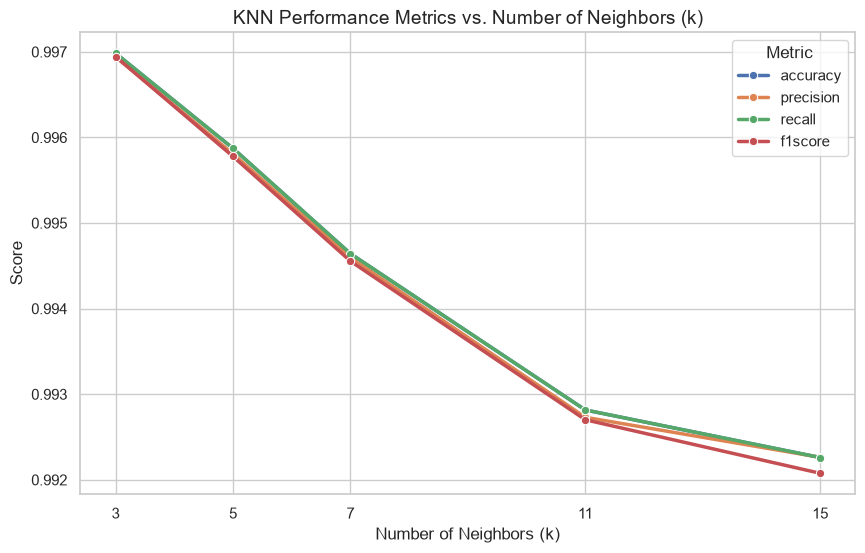

In [33]:


# 1. Convert to DataFrame and transpose
df = pd.DataFrame(resultats).T

# 2. Cast columns to proper numeric types (fixes the object dtype issue)
metrics = ['accuracy', 'precision', 'recall', 'f1score']
for col in metrics:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['neighbors'] = pd.to_numeric(df['neighbors'], errors='coerce', downcast='integer')

# 3. Reshape into long format
df_long = df.melt(id_vars=['neighbors'], value_vars=metrics, var_name='Metric', value_name='Score')

# 4. Plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=df_long, 
    x='neighbors', 
    y='Score', 
    hue='Metric', 
    marker='o', 
    linewidth=2.5
)

plt.title('KNN Performance Metrics vs. Number of Neighbors (k)', fontsize=14)
plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.xticks(df['neighbors'].unique())
plt.legend(title='Metric')

plt.show()

Matrice de confusion KNN avec  3 voisins 




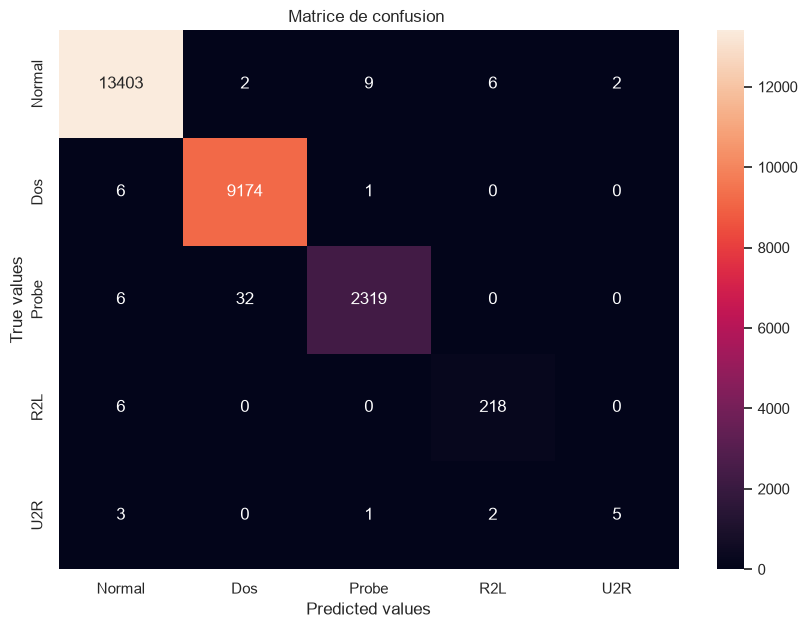

Matrice de confusion KNN avec  5 voisins 




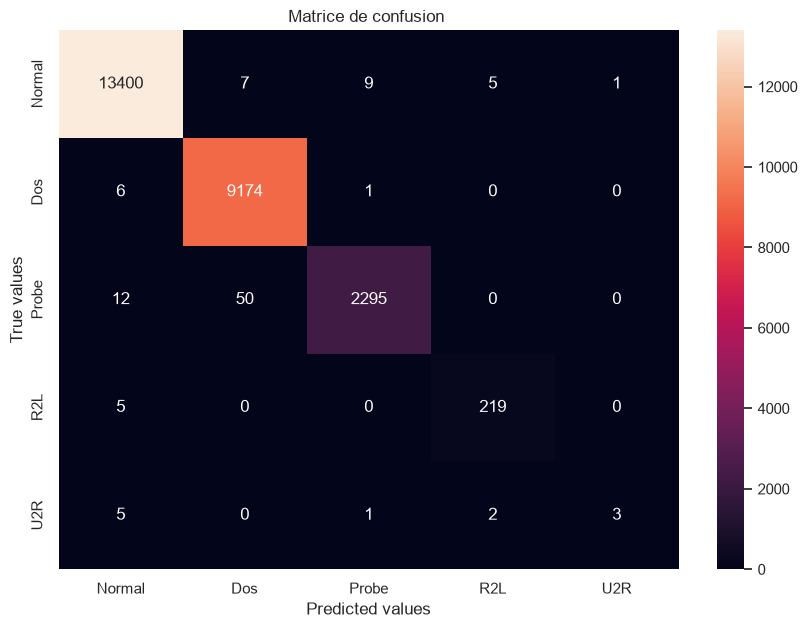

Matrice de confusion KNN avec  7 voisins 




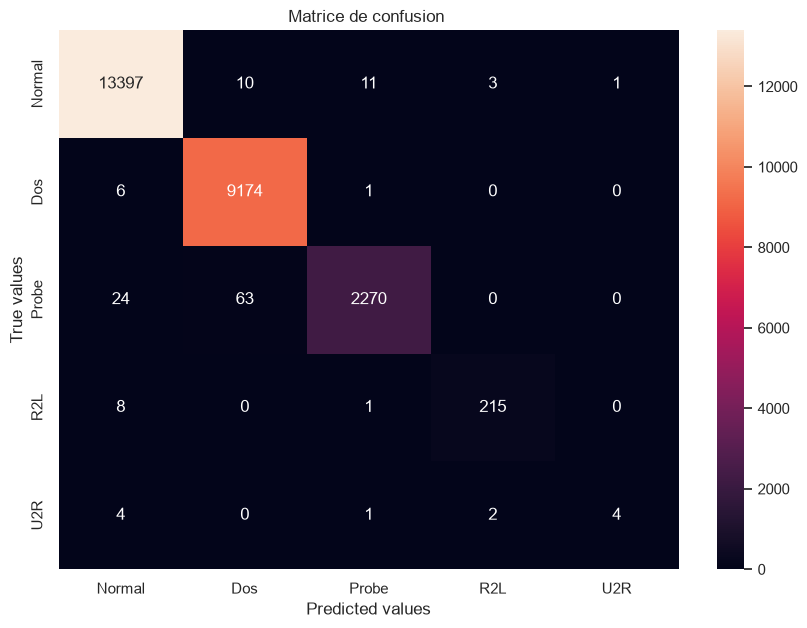

Matrice de confusion KNN avec  11 voisins 




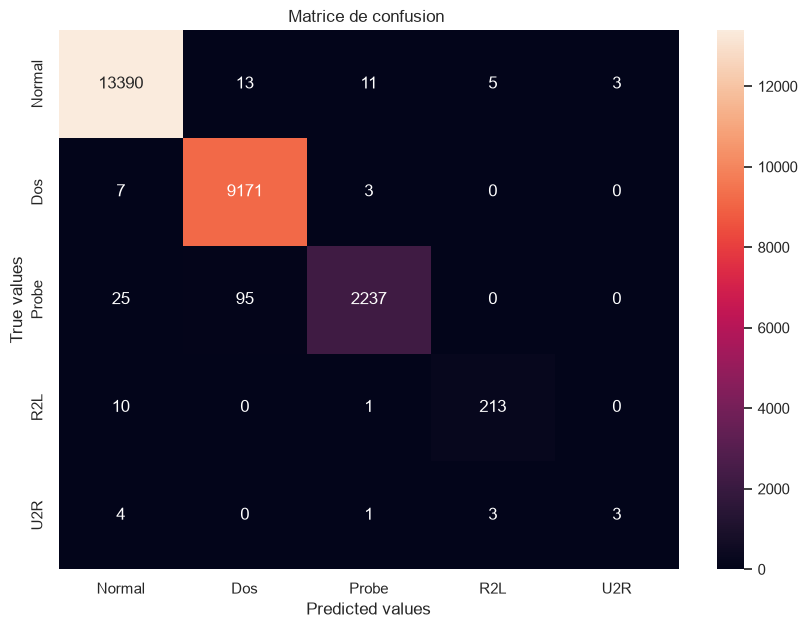

Matrice de confusion KNN avec  15 voisins 




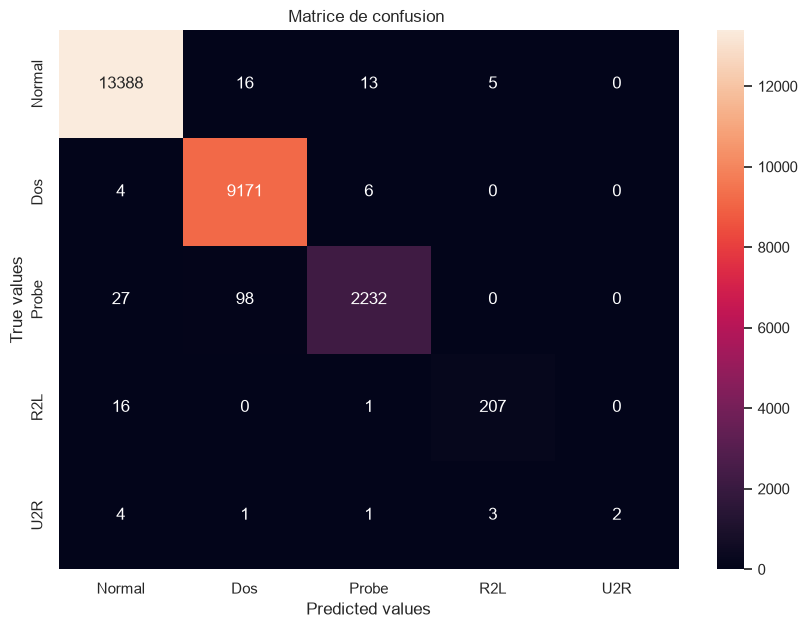

In [34]:
#Matrices de confusion 

def mat_conf(matrix):
    plt.figure(figsize = (10,7))
    sns.heatmap(matrix , annot = True , fmt = "d" , xticklabels=["Normal" , "Dos" , "Probe" , "R2L" , "U2R"] , yticklabels=["Normal" , "Dos" , "Probe" , "R2L" , "U2R"] )
    plt.title("Matrice de confusion ")
    plt.xlabel("Predicted values")
    plt.ylabel("True values")
    plt.show()

for val in range(0,df.shape[0]):
    print("Matrice de confusion KNN avec ",df.iloc[val]["neighbors"],"voisins \n\n")
    mat_conf(df.iloc[val]["confusion_matrix"])



*choix optimal de voisins :* **3**

Les performances du model deminuent en incrementant le nombre de voisins  

In [35]:
# Choix de configuration 

knn_model_final = construct_kn(3)


neighbors  :  3



accuracy  :  0.7519960965223563



precision  :  0.7885359786180287



recall  :  0.7519960965223563



f1score  :  0.7191846387834738





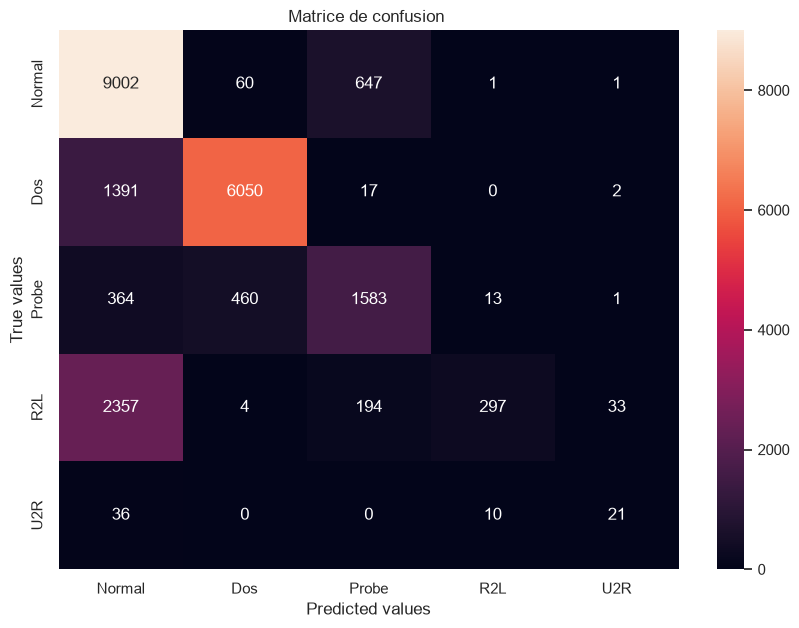

In [37]:
# évaluation du modele sur le jeu de test

y_prediction_test = prediction(knn_model_final,x_test)

knn_evaluation = eval_kn(y_prediction_test,y_test)
for key,value in knn_evaluation.items() :
    if key == "confusion_matrix":
        mat_conf(knn_evaluation["confusion_matrix"])
        break
    print(key ," : " ,  value)
    print("\n\n")




#### **2.Naive Bayes**